In [1]:
from pathlib import Path
from decimal import Decimal
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ============================================================
# 1. SETUP: same Comparison folder and LR colors as before
# ============================================================
DATA_DIR = Path("Comparison") if Path("Comparison").is_dir() else Path(".")
OUTPUT_DIR = Path("reward_cost_figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {
    Decimal("0.000001"): "navy",
    Decimal("0.00001"): "orange",
    Decimal("0.0001"): "crimson",
}
EXTRA_COLORS = ["green", "purple", "teal", "brown", "black"]
SAVE_FIGURES = True
# 1 plots raw histories; increase for optional moving-average smoothing.
SMOOTH_WINDOW = 1

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 1.0,
    "savefig.dpi": 600,
})

# Supports ..._45_nodes_lr_0_00001.npz and decimal-dot LR suffixes.
FILE_PATTERN = re.compile(
    r"(?P<nodes>\d+)[ _-]*nodes[ _-]*lr[_-]*(?P<lr>\d+[_.]\d+)\.npz$",
    re.IGNORECASE,
)

METRICS = (
    ("agent1_reward", "Agent 1 Reward", "agent1_reward"),
    ("agent2_reward", "Agent 2 Reward", "agent2_reward"),
    ("agent1_cost", "Agent 1 Cost", "agent1_cost"),
    ("agent2_cost", "Agent 2 Cost", "agent2_cost"),
)


def as_rate(value):
    return Decimal(str(value).replace("_", "."))


def load_metric(archive, key, lr, path):
    # Normally the histories are stored under unsuffixed keys, e.g. agent1_reward.
    # An LR-suffixed variant is accepted only if it matches the filename's LR.
    candidates = [key] + [
        candidate for candidate in archive.files
        if candidate.startswith(key + "_lr_")
        and as_rate(candidate[len(key + "_lr_"):]) == lr
    ]
    present = [candidate for candidate in candidates if candidate in archive.files]
    if not present:
        raise KeyError(
            f"{path.name}: missing '{key}' for LR={lr}. "
            f"Available keys: {archive.files}. "
            "Save agent1_reward, agent2_reward, agent1_cost, "
            "and agent2_cost in each training archive."
        )
    arr = np.asarray(archive[present[0]], dtype=np.float64)
    if arr.ndim != 1 or arr.size == 0 or not np.all(np.isfinite(arr)):
        raise ValueError(f"{path.name}: {present[0]} must be a nonempty, finite 1-D array; got {arr.shape}.")
    return arr


# ============================================================
# 2. LOAD ALL NODE CONFIGURATIONS AND LEARNING RATES
# ============================================================
# histories[(node_count, Decimal(LR))][metric_name] = 1-D per-episode array
histories = {}
for path in sorted(DATA_DIR.glob("*.npz")):
    match = FILE_PATTERN.search(path.name)
    if not match:
        continue
    nodes = int(match.group("nodes"))
    lr = as_rate(match.group("lr"))
    lookup = (nodes, lr)
    if lookup in histories:
        raise ValueError(f"Duplicate file for {nodes} nodes and LR={lr}: {path}")
    with np.load(path, allow_pickle=False) as archive:
        histories[lookup] = {
            key: load_metric(archive, key, lr, path)
            for key, _, _ in METRICS
        }
    counts = {key: len(arr) for key, arr in histories[lookup].items()}
    print(f"Loaded: {nodes} nodes | LR={lr} | lengths={counts}")

if not histories:
    raise FileNotFoundError(
        f"No matching node/LR .npz archives found in {DATA_DIR.resolve()}. "
        "Expected filename format: ha2c_training_results_45_nodes_lr_0_00001.npz"
    )

NODES = sorted({nodes for nodes, _ in histories})
LEARNING_RATES = sorted({lr for _, lr in histories})
for i, lr in enumerate(lr for lr in LEARNING_RATES if lr not in COLORS):
    COLORS[lr] = EXTRA_COLORS[i % len(EXTRA_COLORS)]
print("Detected nodes:", NODES)
print("Detected learning rates:", [str(lr) for lr in LEARNING_RATES])


# ============================================================
# 3. PLOT HELPER: 4 plots for one node configuration
# ============================================================
def displayed_history(values):
    if not isinstance(SMOOTH_WINDOW, int) or SMOOTH_WINDOW < 1:
        raise ValueError("SMOOTH_WINDOW must be a positive integer.")
    if SMOOTH_WINDOW > len(values):
        raise ValueError(f"SMOOTH_WINDOW={SMOOTH_WINDOW} exceeds {len(values)} episodes.")
    if SMOOTH_WINDOW == 1:
        return np.arange(1, len(values) + 1), values
    smoothed = np.convolve(
        values, np.ones(SMOOTH_WINDOW) / SMOOTH_WINDOW, mode="valid"
    )
    # End-of-window alignment retains the episode number in the original history.
    return np.arange(SMOOTH_WINDOW, len(values) + 1), smoothed


def plot_metric_for_node(nodes, metric_key, ylabel, filename_stem):
    available_lrs = sorted(lr for n, lr in histories if n == nodes)
    if not available_lrs:
        raise ValueError(f"No data found for {nodes} nodes. Available nodes: {NODES}")

    fig, ax = plt.subplots(figsize=(4.5, 4.0))
    all_x, all_y = [], []
    for lr in available_lrs:
        episodes, values = displayed_history(histories[(nodes, lr)][metric_key])
        ax.plot(episodes, values, label=f"LR = {lr}",
                color=COLORS[lr], linestyle="--", linewidth=1.45)
        all_x.append(episodes)
        all_y.append(values)

    # Independently derive the limits from this metric's actual plotted data.
    xmin = min(float(np.min(x)) for x in all_x)
    xmax = max(float(np.max(x)) for x in all_x)
    if xmax == xmin:  # A one-episode trace still needs a nonzero x-axis span.
        ax.set_xlim(xmin - 0.5, xmax + 0.5)
    else:
        ax.set_xlim(xmin, xmax)

    ymin = min(float(np.min(y)) for y in all_y)
    ymax = max(float(np.max(y)) for y in all_y)
    y_range = ymax - ymin
    # Percentage-based padding; constant-valued traces get a nonzero dynamic span.
    y_pad = 0.05 * (y_range if y_range > 0 else max(abs(ymin), 1.0))
    ax.set_ylim(ymin - y_pad, ymax + y_pad)

    ax.set_xlabel("Episode")  # The saved histories are per training episode.
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(True, which="major", linestyle="--", color="gray",
            linewidth=0.75, alpha=0.6)
    ax.tick_params(axis="both", which="major", direction="in",
                   length=5, width=1.0, labelsize=9)
    ax.legend(loc="best", frameon=True, framealpha=0.95,
              edgecolor="lightgray", fontsize=9)
    fig.tight_layout()

    if SAVE_FIGURES:
        suffix = "raw" if SMOOTH_WINDOW == 1 else f"ma_{SMOOTH_WINDOW}"
        filename = OUTPUT_DIR / f"{filename_stem}_{nodes}_nodes_{suffix}.png"
        fig.savefig(filename, dpi=600, bbox_inches="tight")
        print(f"Saved: {filename}")
    plt.show()
    plt.close(fig)  # Do not return fig: avoids duplicate Jupyter display.


def plot_node_lr_comparison(nodes):
    """Exactly four plots: agent1 reward, agent2 reward, agent1 cost, agent2 cost."""
    for metric_key, ylabel, filename_stem in METRICS:
        plot_metric_for_node(nodes, metric_key, ylabel, filename_stem)


Loaded: 45 nodes | LR=0.000001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_cost': 2000, 'agent2_cost': 2000}
Loaded: 45 nodes | LR=0.00001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_cost': 2000, 'agent2_cost': 2000}
Loaded: 45 nodes | LR=0.0001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_cost': 2000, 'agent2_cost': 2000}
Loaded: 55 nodes | LR=0.000001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_cost': 2000, 'agent2_cost': 2000}
Loaded: 55 nodes | LR=0.00001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_cost': 2000, 'agent2_cost': 2000}
Loaded: 55 nodes | LR=0.0001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_cost': 2000, 'agent2_cost': 2000}
Loaded: 65 nodes | LR=0.000001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_cost': 2000, 'agent2_cost': 2000}
Loaded: 65 nodes | LR=0.00001 | lengths={'agent1_reward': 2000, 'agent2_reward': 2000, 'agent1_c

## 45 nodes

Saved: reward_cost_figures/agent1_reward_45_nodes_raw.png


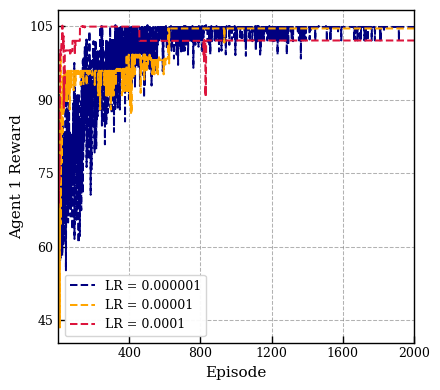

Saved: reward_cost_figures/agent2_reward_45_nodes_raw.png


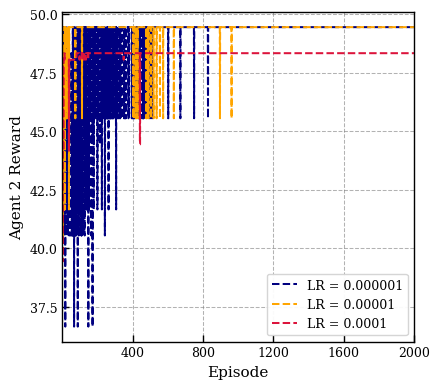

Saved: reward_cost_figures/agent1_cost_45_nodes_raw.png


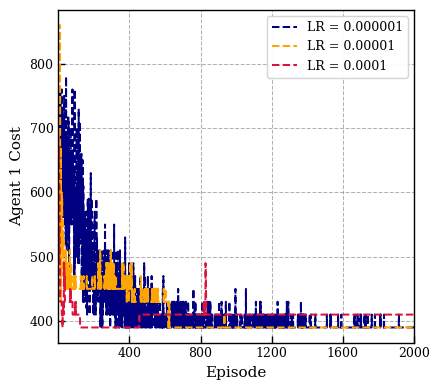

Saved: reward_cost_figures/agent2_cost_45_nodes_raw.png


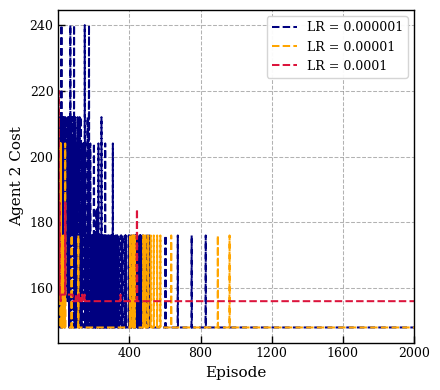

In [2]:
plot_node_lr_comparison(45)

## 55 nodes

Saved: reward_cost_figures/agent1_reward_55_nodes_raw.png


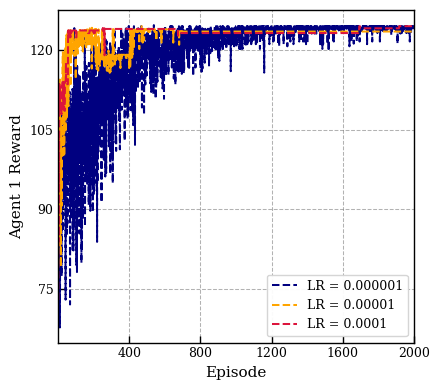

Saved: reward_cost_figures/agent2_reward_55_nodes_raw.png


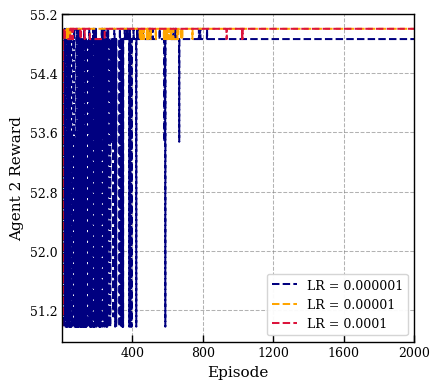

Saved: reward_cost_figures/agent1_cost_55_nodes_raw.png


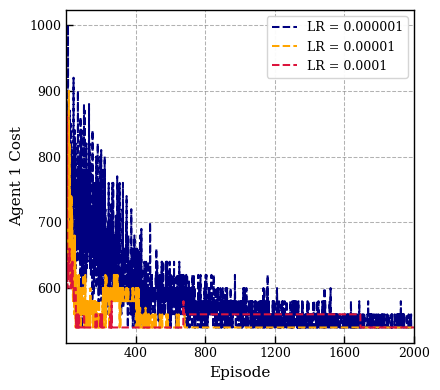

Saved: reward_cost_figures/agent2_cost_55_nodes_raw.png


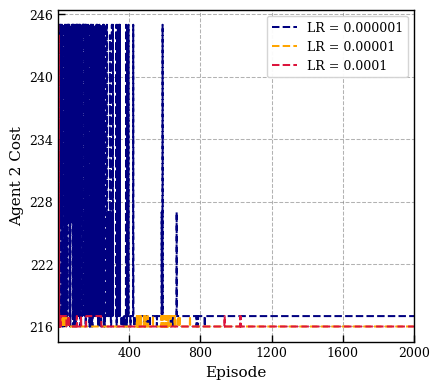

In [3]:
plot_node_lr_comparison(55)

## 65 nodes

Saved: reward_cost_figures/agent1_reward_65_nodes_raw.png


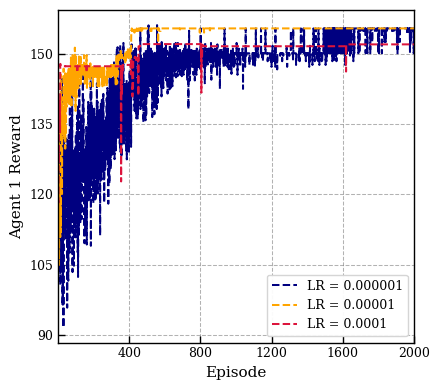

Saved: reward_cost_figures/agent2_reward_65_nodes_raw.png


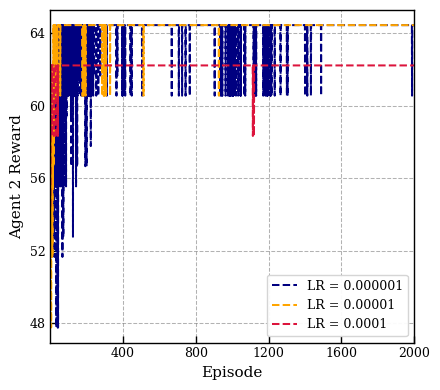

Saved: reward_cost_figures/agent1_cost_65_nodes_raw.png


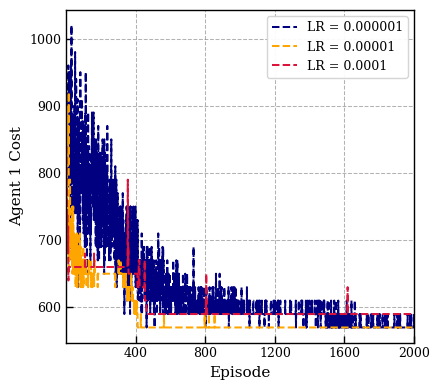

Saved: reward_cost_figures/agent2_cost_65_nodes_raw.png


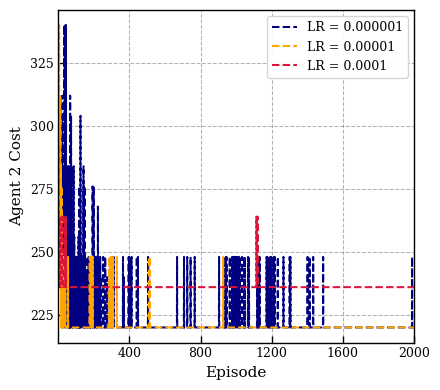

In [4]:
plot_node_lr_comparison(65)

## Other node configurations (optional)
Call `plot_node_lr_comparison(node_count)` for another detected node, or uncomment the loop below to plot every node.

In [5]:
# for nodes in NODES:
#     plot_node_lr_comparison(nodes)